In [ ]:
pip install yfinance pandas numpy matplotlib scikit-learn

In [2]:
import yfinance as yf
import pandas as pd
import numpy as np

In [3]:
ticker = "RELIANCE.NS"
df = yf.download(
    ticker,
    start="2020-01-01",
    end="2026-08-01",
    auto_adjust=True
)
df

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS
Date,,,,,
2020-01-01,672.216064,680.008728,670.390410,675.956548,14004468
2020-01-02,683.660278,686.176208,673.284921,673.284921,17710316
2020-01-03,684.484070,686.487896,678.183128,682.636062,20984698
2020-01-06,668.609314,680.365044,667.050769,676.847260,24519177
2020-01-07,678.895569,683.303975,673.952766,676.401873,16683622
...,...,...,...,...,...
2026-07-27,1280.000000,1288.699951,1278.000000,1288.199951,7163132
2026-07-28,1267.699951,1279.199951,1265.900024,1275.000000,9312184


In [4]:
df.columns = df.columns.get_level_values(0)
print(df.head())

Price            Close        High         Low        Open    Volume
Date                                                                
2020-01-01  672.216064  680.008728  670.390410  675.956548  14004468
2020-01-02  683.660278  686.176208  673.284921  673.284921  17710316
2020-01-03  684.484070  686.487896  678.183128  682.636062  20984698
2020-01-06  668.609314  680.365044  667.050769  676.847260  24519177
2020-01-07  678.895569  683.303975  673.952766  676.401873  16683622


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1633 entries, 2020-01-01 to 2026-07-31
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   1633 non-null   float64
 1   High    1633 non-null   float64
 2   Low     1633 non-null   float64
 3   Open    1633 non-null   float64
 4   Volume  1633 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 76.5 KB


In [6]:
df.isnull().sum()

,0
Price,
Close,0
High,0
Low,0
Open,0
Volume,0


In [7]:
df.describe()

Price,Close,High,Low,Open,Volume
count,1633.000000,1633.000000,1633.000000,1633.000000,1.633000e+03
mean,1162.214173,1174.176383,1151.233883,1162.945467,1.790641e+07
std,238.017338,238.235461,237.693903,237.884366,1.465737e+07
min,393.662384,423.029534,389.921900,407.978572,0.000000e+00
25%,1016.732910,1030.342889,1004.805600,1020.038404,9.611974e+06
50%,1175.201050,1185.518454,1163.998979,1174.832463,1.344017e+07
75%,1358.988892,1371.657986,1349.718970,1358.916848,2.038580e+07
max,1584.971802,1604.382010,1570.936597,1585.668486,1.426834e+08


In [ ]:
df.columns

Index(['Close', 'High', 'Low', 'Open', 'Volume'], dtype='object', name='Price')

In [8]:
Q1 = df["Close"].quantile(0.25)
Q3 = df["Close"].quantile(0.75)
IQR = Q3 - Q1
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR
outliers = df[
    (df["Close"] < lower_limit) |
    (df["Close"] > upper_limit)
]
print("Number of Outliers:", len(outliers))
print(outliers["Close"])

Number of Outliers: 17
Date
2020-03-09    496.124573
2020-03-12    473.347748
2020-03-13    492.183746
2020-03-16    452.285339
2020-03-17    448.856628
2020-03-18    431.267487
2020-03-19    408.646515
2020-03-20    453.287231
2020-03-23    393.662384
2020-03-24    420.090576
2020-03-25    481.919647
2020-03-26    474.772705
2020-03-27    474.505554
2020-03-30    458.853424
2020-03-31    495.946472
2020-04-01    481.118195
2020-04-03    479.782288
Name: Close, dtype: float64


In [9]:
Q1 = df["Open"].quantile(0.25)
Q3 = df["Open"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["Open"] < lower_limit) |
    (df["Open"] > upper_limit)
]

print("Number of Outliers:", len(outliers))

print(outliers["Open"])

Number of Outliers: 18
Date
2020-03-11    493.386079
2020-03-12    483.144238
2020-03-13    444.403667
2020-03-16    472.256780
2020-03-17    466.334405
2020-03-18    456.560192
2020-03-19    409.715220
2020-03-20    418.353887
2020-03-23    407.978572
2020-03-24    414.123625
2020-03-25    429.174566
2020-03-26    487.953425
2020-03-27    487.597218
2020-03-30    463.373180
2020-03-31    478.223761
2020-04-01    499.731469
2020-04-03    505.164079
2020-04-07    490.758780
Name: Open, dtype: float64


In [10]:
df["Previous_Close"] = df["Close"].shift(1)

df["Previous_Close"]

,Previous_Close
Date,
2020-01-01,NaN
2020-01-02,672.216064
2020-01-03,683.660278
2020-01-06,684.484070
2020-01-07,668.609314
...,...
2026-07-27,1278.000000
2026-07-28,1280.000000
2026-07-29,1267.699951


In [11]:
df['Daily_Return']=df['Close'].pct_change()*100

df['Daily_Return']

,Daily_Return
Date,
2020-01-01,NaN
2020-01-02,1.702461
2020-01-03,0.120497
2020-01-06,-2.319229
2020-01-07,1.538455
...,...
2026-07-27,0.156495
2026-07-28,-0.960941
2026-07-29,0.646847


In [12]:
df['Price_Difference']=df['Close']-df['Previous_Close']

df['Price_Difference']

,Price_Difference
Date,
2020-01-01,NaN
2020-01-02,11.444214
2020-01-03,0.823792
2020-01-06,-15.874756
2020-01-07,10.286255
...,...
2026-07-27,2.000000
2026-07-28,-12.300049
2026-07-29,8.200073


In [13]:
df['MA5']=df['Close'].rolling(5).mean()
df['MA10']=df['Close'].rolling(10).mean()
df['MA20']=df['Close'].rolling(20).mean()
df['MA50']=df['Close'].rolling(50).mean()
df['MA100']=df['Close'].rolling(100).mean()
df['MA200']=df['Close'].rolling(200).mean()

print(df[['Close','MA5','MA10','MA20','MA50','MA100','MA200']].head(10))

Price            Close         MA5        MA10  MA20  MA50  MA100  MA200
Date                                                                    
2020-01-01  672.216064         NaN         NaN   NaN   NaN    NaN    NaN
2020-01-02  683.660278         NaN         NaN   NaN   NaN    NaN    NaN
2020-01-03  684.484070         NaN         NaN   NaN   NaN    NaN    NaN
2020-01-06  668.609314         NaN         NaN   NaN   NaN    NaN    NaN
2020-01-07  678.895569  677.573059         NaN   NaN   NaN    NaN    NaN
2020-01-08  673.796997  677.889246         NaN   NaN   NaN    NaN    NaN
2020-01-09  689.315430  679.020276         NaN   NaN   NaN    NaN    NaN
2020-01-10  689.159607  679.955383         NaN   NaN   NaN    NaN    NaN
2020-01-13  687.400757  683.713672         NaN   NaN   NaN    NaN    NaN
2020-01-14  681.033081  684.141174  680.857117   NaN   NaN    NaN    NaN


In [14]:
df['High_Low_Range']=df['High']-df['Low']

df['High_Low_Range']

,High_Low_Range
Date,
2020-01-01,9.618318
2020-01-02,12.891288
2020-01-03,8.304769
2020-01-06,13.314275
2020-01-07,9.351209
...,...
2026-07-27,10.699951
2026-07-28,13.299927
2026-07-29,13.700073


In [15]:
df['Open_Close_Range']=df['Open']-df['Close']

df['Open_Close_Range']

,Open_Close_Range
Date,
2020-01-01,3.740483
2020-01-02,-10.375358
2020-01-03,-1.848008
2020-01-06,8.237946
2020-01-07,-2.493695
...,...
2026-07-27,8.199951
2026-07-28,7.300049
2026-07-29,-0.900024


In [16]:
df["Volatility_10"] = (
    df["Daily_Return"]
    .rolling(10)
    .std()
)

df

Price,Close,High,Low,Open,Volume,Previous_Close,Daily_Return,Price_Difference,MA5,MA10,MA20,MA50,MA100,MA200,High_Low_Range,Open_Close_Range,Volatility_10
Date,,,,,,,,,,,,,,,,,
2020-01-01,672.216064,680.008728,670.390410,675.956548,14004468,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.618318,3.740483,NaN
2020-01-02,683.660278,686.176208,673.284921,673.284921,17710316,672.216064,1.702461,11.444214,NaN,NaN,NaN,NaN,NaN,NaN,12.891288,-10.375358,NaN
2020-01-03,684.484070,686.487896,678.183128,682.636062,20984698,683.660278,0.120497,0.823792,NaN,NaN,NaN,NaN,NaN,NaN,8.304769,-1.848008,NaN
2020-01-06,668.609314,680.365044,667.050769,676.847260,24519177,684.484070,-2.319229,-15.874756,NaN,NaN,NaN,NaN,NaN,NaN,13.314275,8.237946,NaN
2020-01-07,678.895569,683.303975,673.952766,676.401873,16683622,668.609314,1.538455,10.286255,677.573059,NaN,NaN,NaN,NaN,NaN,9.351209,-2.493695,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-07-27,1280.000000,1288.699951,1278.000000,1288.199951,7163132,1278.000000,0.156495,2.000000,1284.499976,1295.789978,1297.870001,1307.841907,1340.317340,1406.272682,10.699951,8.199951,1.104832
2026-07-28,1267.699951,1279.199951,1265.900024,1275.000000,9312184,1280.000000,-0.960941,-12.300049,1277.299976,1293.259973,1296.559998,1306.863657,1339.606240,1405.805648,13.299927,7.300049,1.135752
2026-07-29,1275.900024,1282.400024,1268.699951,1275.000000,9448307,1267.699951,0.646847,8.200073,1274.759985,1291.299976,1294.954999,1305.312815,1338.535184,1405.327853,13.700073,-0.900024,1.161592


In [17]:
df=df.dropna()

In [18]:
df

Price,Close,High,Low,Open,Volume,Previous_Close,Daily_Return,Price_Difference,MA5,MA10,MA20,MA50,MA100,MA200,High_Low_Range,Open_Close_Range,Volatility_10
Date,,,,,,,,,,,,,,,,,
2020-10-19,982.215759,1005.911361,972.714991,988.466892,31200385,982.035156,0.018391,0.180603,1004.394836,1006.692169,1004.649826,985.900521,903.409756,755.153756,33.196370,6.251132,1.613950
2020-10-20,973.053406,989.798282,971.405965,983.479460,18482288,982.215759,-0.932825,-9.162354,993.129248,1004.234595,1002.394229,986.225940,906.306086,756.657943,18.392318,10.426054,1.632183
2020-10-21,958.926392,989.347020,946.807768,978.514760,34082321,973.053406,-1.451823,-14.127014,978.424438,998.236230,1000.441037,986.142893,908.992145,758.034273,42.539251,19.588369,1.435612
2020-10-22,950.960083,962.491933,943.761161,960.190087,30802210,958.926392,-0.830753,-7.966309,969.438159,992.264935,997.646085,985.956488,911.571794,759.366653,18.730772,9.230004,1.435998
2020-10-23,953.713318,963.620290,946.198445,950.531313,23422125,950.960083,0.289522,2.753235,963.773792,986.830743,996.108127,985.875247,914.007487,760.792173,17.421844,-3.182005,1.460641
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-07-27,1280.000000,1288.699951,1278.000000,1288.199951,7163132,1278.000000,0.156495,2.000000,1284.499976,1295.789978,1297.870001,1307.841907,1340.317340,1406.272682,10.699951,8.199951,1.104832
2026-07-28,1267.699951,1279.199951,1265.900024,1275.000000,9312184,1280.000000,-0.960941,-12.300049,1277.299976,1293.259973,1296.559998,1306.863657,1339.606240,1405.805648,13.299927,7.300049,1.135752
2026-07-29,1275.900024,1282.400024,1268.699951,1275.000000,9448307,1267.699951,0.646847,8.200073,1274.759985,1291.299976,1294.954999,1305.312815,1338.535184,1405.327853,13.700073,-0.900024,1.161592


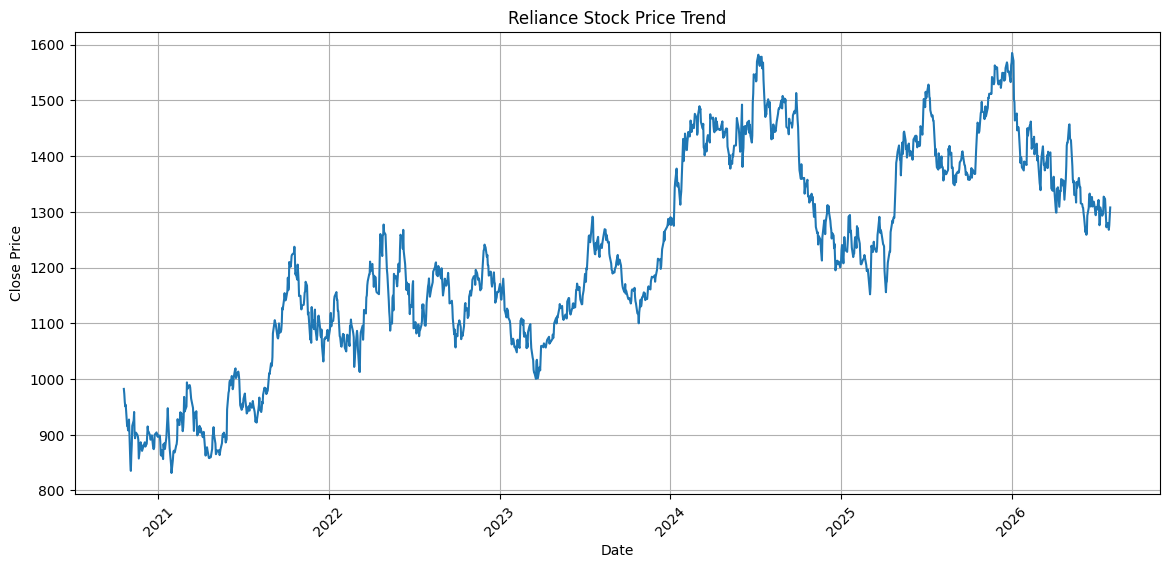

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(df["Close"])

plt.title("Reliance Stock Price Trend")
plt.xlabel("Date")
plt.ylabel("Close Price")

plt.xticks(rotation=45)
plt.grid()
plt.show()

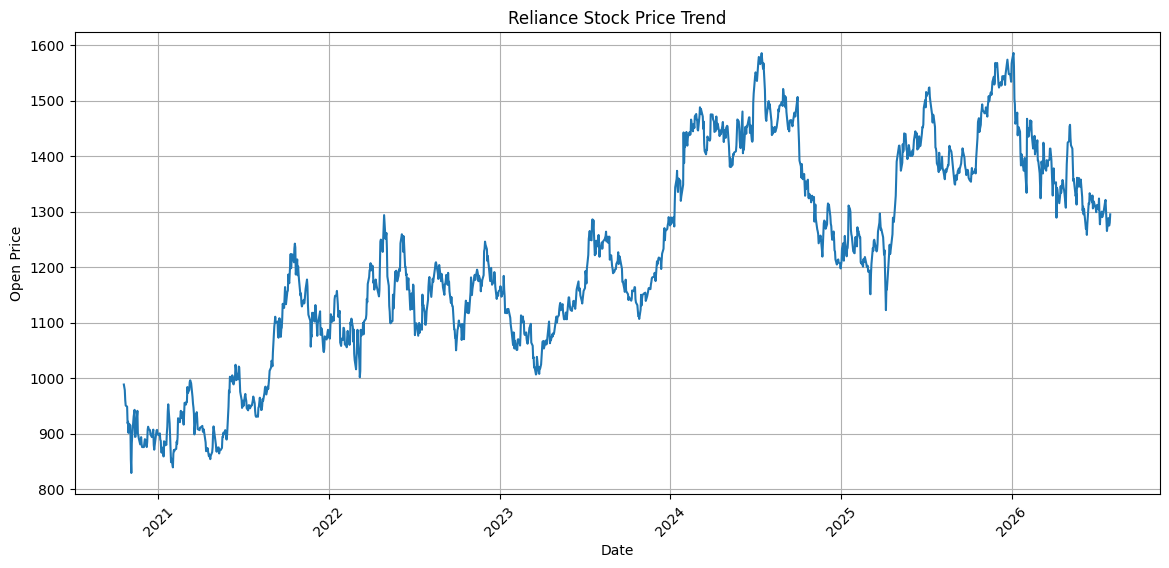

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(df["Open"])

plt.title("Reliance Stock Price Trend")
plt.xlabel("Date")
plt.ylabel("Open Price")

plt.xticks(rotation=45)
plt.grid()
plt.show()

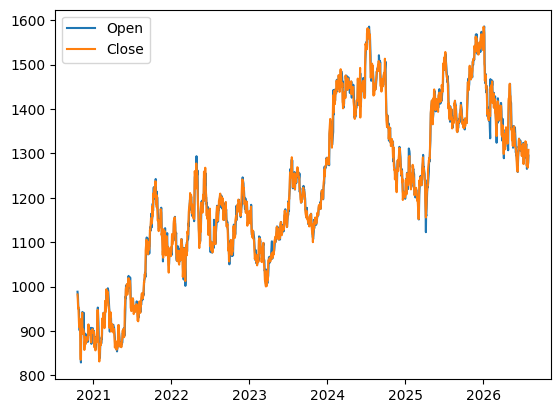

In [21]:
plt.plot(df['Open'],label='Open')
plt.plot(df['Close'],label='Close')
plt.legend()
plt.show()

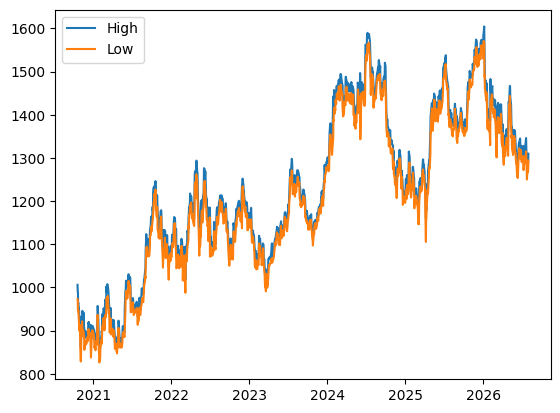

In [22]:
plt.plot(df['High'],label='High')
plt.plot(df['Low'],label='Low')
plt.legend()
plt.show()

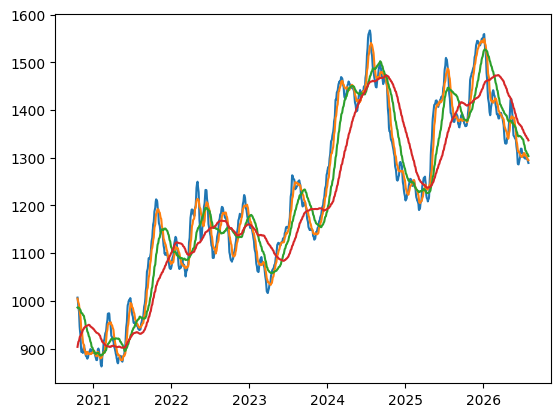

In [23]:
plt.plot(df['MA10'],label='MA10')
plt.plot(df['MA20'],label='MA20')
plt.plot(df['MA50'],label='MA50')
plt.plot(df['MA100'],label='MA100')
plt.show()

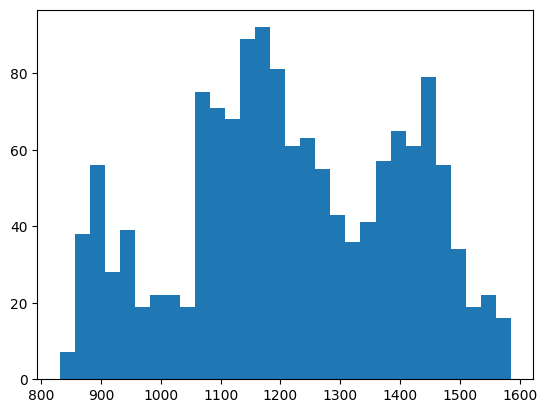

In [24]:
plt.hist(df['Close'],bins=30)
plt.show()

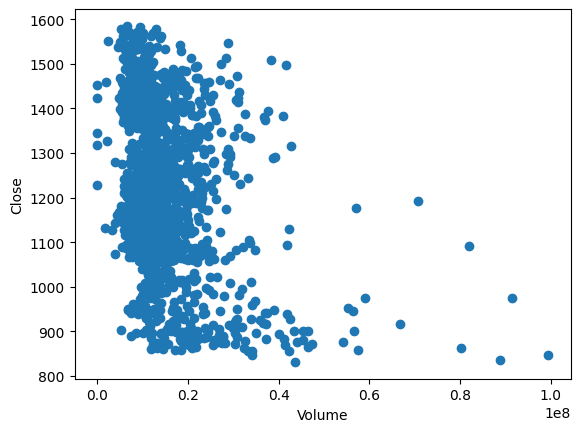

In [25]:
plt.scatter(df['Volume'],df['Close'])
plt.xlabel('Volume')
plt.ylabel('Close')
plt.show()

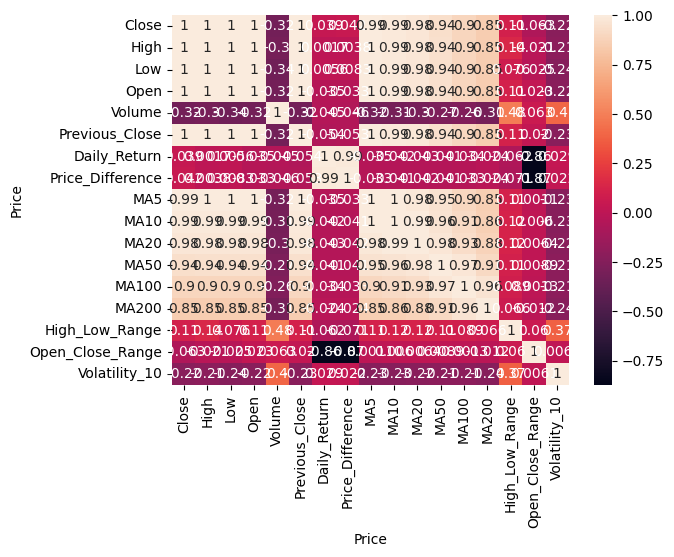

In [28]:
import seaborn as sns

sns.heatmap(df.corr(numeric_only=True),annot=True)
plt.show()


In [29]:
df.columns

Index(['Close', 'High', 'Low', 'Open', 'Volume', 'Previous_Close',
       'Daily_Return', 'Price_Difference', 'MA5', 'MA10', 'MA20', 'MA50',
       'MA100', 'MA200', 'High_Low_Range', 'Open_Close_Range',
       'Volatility_10'],
      dtype='object', name='Price')

In [30]:
df.shape

(1434, 17)

In [33]:
features=['High','Low','Open','Volume','MA5',
          'MA10','MA20','MA50','MA100','MA200','Volatility_10']
target=['Close']

In [34]:
from sklearn.model_selection import train_test_split

X=df[features]
y=df[target]
X_train,X_test,y_train,y_test=train_test_split(
    df[features],df[target],test_size=0.2,random_state=42
)

In [35]:
from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [37]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,r2_score

model=LinearRegression()
model.fit(X_train,y_train)
y_pred=model.predict(X_test)


mse=mean_squared_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)

print(f'Mean Squared Error: {mse}')
print(f'R-squared: {r2}')

Mean Squared Error: 34.84985541024874
R-squared: 0.9989136015164022


In [38]:
from sklearn.ensemble import RandomForestRegressor

model=RandomForestRegressor(n_estimators=100,random_state=42)
model.fit(X_train,y_train)
y_pred=model.predict(X_test)


mse=mean_squared_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)

print(f'Mean Squared Error: {mse}')
print(f'R-squared: {r2}')

/usr/local/lib/python3.12/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Mean Squared Error: 80.83363524177781
R-squared: 0.9974801175581193
